vérifier le GPU

In [ ]:
import torch
print("GPU disponible :", torch.cuda.is_available())

GPU disponible : True


installer Detectron2

In [ ]:
!pip install -q 'git+https://github.com/facebookresearch/detectron2.git' --no-build-isolation

  Preparing metadata (pyproject.toml) ... done


téléverser l’image

In [ ]:
from google.colab import files
uploaded = files.upload()
nom_image = next(iter(uploaded))
print("Image reçue :", nom_image)

Saving nom_image1.jpg to nom_image1.jpg
Image reçue : nom_image1.jpg


charger le modèle Mask R-CNN

In [ ]:
import cv2
import matplotlib.pyplot as plt
from detectron2.engine import DefaultPredictor
from detectron2.config import get_cfg
from detectron2 import model_zoo
from detectron2.utils.visualizer import Visualizer
from detectron2.data import MetadataCatalog

CONFIG = "COCO-InstanceSegmentation/mask_rcnn_R_50_FPN_3x.yaml"

cfg = get_cfg()
cfg.merge_from_file(model_zoo.get_config_file(CONFIG))
cfg.MODEL.ROI_HEADS.SCORE_THRESH_TEST = 0.5
cfg.MODEL.WEIGHTS = model_zoo.get_checkpoint_url(CONFIG)
if not torch.cuda.is_available():
    cfg.MODEL.DEVICE = "cpu"

predictor = DefaultPredictor(cfg)
print("Modèle chargé sur :", cfg.MODEL.DEVICE)

/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/detectron2/model_zoo/model_zoo.py:4: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
model_final_f10217.pkl: 178MB [00:00, 263MB/s]                           


Modèle chargé sur : cuda


détection et affichage des masques

/usr/local/lib/python3.13/dist-packages/torch/functional.py:504: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/native/TensorShape.cpp:4221.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]
W1114 12:02:40.026000 4802 torch/fx/_symbolic_trace.py:57] is_fx_tracing will return true for both fx.symbolic_trace and torch.export. Please use is_fx_tracing_symbolic_tracing() for specifically fx.symbolic_trace or torch.compiler.is_compiling() for specifically torch.export/compile.


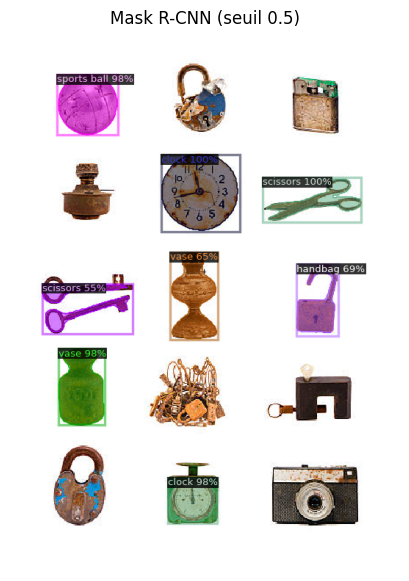

In [ ]:
img = cv2.imread(nom_image)
assert img is not None, "Image introuvable"

outputs = predictor(img)

v = Visualizer(img[:, :, ::-1], MetadataCatalog.get(cfg.DATASETS.TRAIN[0]), scale=1.2)
out = v.draw_instance_predictions(outputs["instances"].to("cpu"))

plt.figure(figsize=(10, 7))
plt.imshow(out.get_image())
plt.axis("off")
plt.title("Mask R-CNN (seuil 0.5)")
plt.show()

liste des objets détectés

In [ ]:
inst = outputs["instances"].to("cpu")
noms = MetadataCatalog.get(cfg.DATASETS.TRAIN[0]).thing_classes

for classe, score in zip(inst.pred_classes.tolist(), inst.scores.tolist()):
    print(f"{noms[classe]:15s} {score:.0%}")
print("Total :", len(inst), "objet(s)")

clock           100%
scissors        100%
clock           98%
sports ball     98%
vase            98%
handbag         69%
vase            65%
scissors        55%
Total : 8 objet(s)


question 2 : effet du seuil SCORE_THRESH_TEST

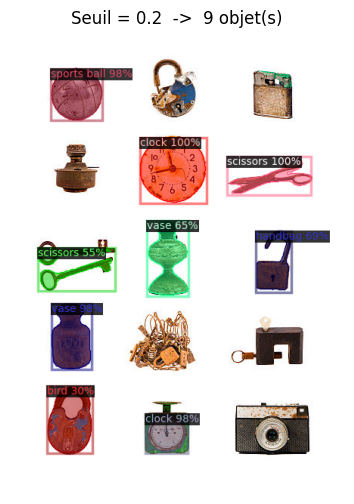

Seuil 0.2 : [('clock', 1.0), ('scissors', 1.0), ('clock', 0.98), ('sports ball', 0.98), ('vase', 0.98), ('handbag', 0.69), ('vase', 0.65), ('scissors', 0.55), ('bird', 0.3)]


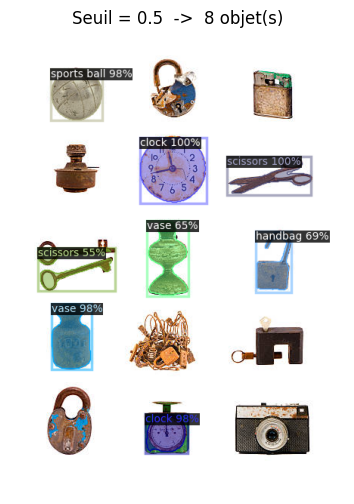

Seuil 0.5 : [('clock', 1.0), ('scissors', 1.0), ('clock', 0.98), ('sports ball', 0.98), ('vase', 0.98), ('handbag', 0.69), ('vase', 0.65), ('scissors', 0.55)]


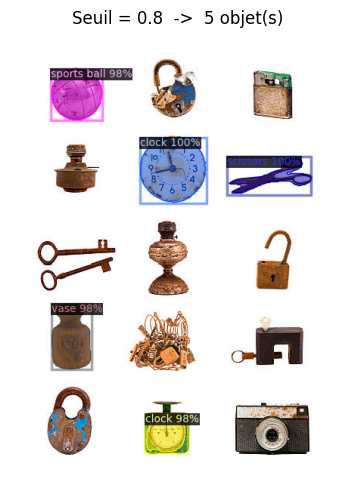

Seuil 0.8 : [('clock', 1.0), ('scissors', 1.0), ('clock', 0.98), ('sports ball', 0.98), ('vase', 0.98)]


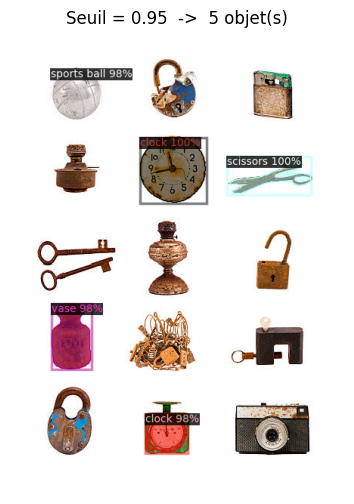

Seuil 0.95 : [('clock', 1.0), ('scissors', 1.0), ('clock', 0.98), ('sports ball', 0.98), ('vase', 0.98)]


In [ ]:
import copy

def detecter(seuil):
    c = copy.deepcopy(cfg)
    c.MODEL.ROI_HEADS.SCORE_THRESH_TEST = seuil
    pred = DefaultPredictor(c)
    sortie = pred(img)
    v = Visualizer(img[:, :, ::-1], MetadataCatalog.get(c.DATASETS.TRAIN[0]), scale=1.0)
    res = v.draw_instance_predictions(sortie["instances"].to("cpu"))
    return res.get_image(), sortie["instances"].to("cpu")

noms = MetadataCatalog.get(cfg.DATASETS.TRAIN[0]).thing_classes

for seuil in [0.2, 0.5, 0.8, 0.95]:
    image_res, inst = detecter(seuil)
    plt.figure(figsize=(8, 6))
    plt.imshow(image_res)
    plt.axis("off")
    plt.title(f"Seuil = {seuil}  ->  {len(inst)} objet(s)")
    plt.show()
    print(f"Seuil {seuil} :", [(noms[c], round(s, 2)) for c, s in zip(inst.pred_classes.tolist(), inst.scores.tolist())])

résumé en tableau

In [ ]:
print("Seuil | Nombre de détections")
for seuil in [0.2, 0.5, 0.8, 0.95]:
    _, inst = detecter(seuil)
    print(f"{seuil:5} | {len(inst)}")

Seuil | Nombre de détections
  0.2 | 9
  0.5 | 8
  0.8 | 5
 0.95 | 5


### Réponses aux questions (Exercice 3)

**1. Quels objets ont été détectés ?**

Sur mon image (seuil 0.5), le modèle a détecté : ... (recopie ici la liste affichée par ton code, avec les scores).

Le modèle est pré-entraîné sur COCO (80 classes). Il ne peut reconnaître que ces classes : pour un objet absent de COCO (tigre, fleur, papillon...), il choisit la classe connue la plus proche, parfois à tort.

**2. Effet du seuil SCORE_THRESH_TEST**

Ce seuil est le score de confiance minimal pour garder une détection.

- Seuil bas (0.2) : plus de détections, mais des faux positifs (objets inventés, masques en double). Bon rappel, précision plus faible.
- Seuil moyen (0.5) : bon compromis, valeur par défaut.
- Seuil haut (0.8 à 0.95) : seules les détections très sûres restent. Peu de fausses alertes, mais des objets réels (petits, partiellement cachés) sont manqués. Bonne précision, rappel plus faible.

Résultats observés : seuil 0.2 -> ... objets, 0.5 -> ... objets, 0.8 -> ... objets, 0.95 -> ... objets.

Le bon seuil dépend de l'application : bas si on ne veut rien rater, haut si une fausse alerte coûte cher.